Sources:
* https://www.kaggle.com/code/andradaolteanu/work-w-audio-data-visualise-classify-recommend

In [3]:
# Usual Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import sklearn

# Librosa (the mother of audio files)
import librosa
import librosa.display
import IPython.display as ipd
import warnings
warnings.filterwarnings('ignore')

In [90]:
import os
general_path = '../BongcayaoTanalgo_ISCS30.63'
print(list(os.listdir(f'{general_path}')))

['.git', '.gitignore', 'beethoven.wav', 'best_model.ckpt', 'conf matrix model1.png', 'conf matrix model2.png', 'conf matrix model3.png', 'conf matrix model4.png', 'conf matrix.png', 'extracted-features', 'genres', 'gtzanvenv', 'project-ver2.ipynb', 'project.ipynb', 'requirements.txt', 'test_filtered.txt', 'train_filtered.txt', 'valid_filtered.txt']


In [91]:
# Importing 1 file
y, sr = librosa.load(f'{general_path}/genres/reggae/reggae.00036.wav')

print('y:', y, '\n')
print('y shape:', np.shape(y), '\n')
print('Sample Rate (KHz):', sr, '\n')

# Verify length of the audio
print('Check Len of Audio:', 661794/22050)

y: [0.02072144 0.04492188 0.05422974 ... 0.06912231 0.08303833 0.08572388] 

y shape: (661794,) 

Sample Rate (KHz): 22050 

Check Len of Audio: 30.013333333333332


In [92]:
# Trim leading and trailing silence from an audio signal (silence before and after the actual audio)
audio_file, _ = librosa.effects.trim(y)

# the result is an numpy ndarray
print('Audio File:', audio_file, '\n')
print('Audio File shape:', np.shape(audio_file))

Audio File: [0.02072144 0.04492188 0.05422974 ... 0.06912231 0.08303833 0.08572388] 

Audio File shape: (661794,)


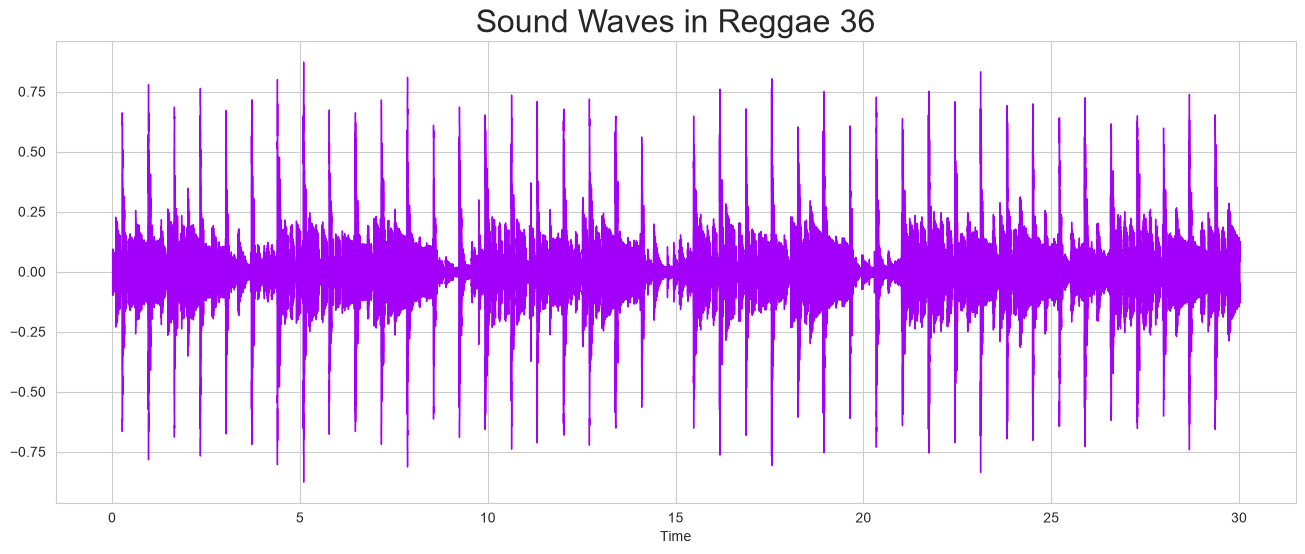

In [93]:
plt.figure(figsize = (16, 6))
librosa.display.waveshow(y = audio_file, sr = sr, color = "#A300F9");
plt.title("Sound Waves in Reggae 36", fontsize = 23);

In [94]:
# Default FFT window size
n_fft = 2048 # FFT window size
hop_length = 512 # number audio of frames between STFT columns (looks like a good default)

# Short-time Fourier transform (STFT)
D = np.abs(librosa.stft(audio_file, n_fft = n_fft, hop_length = hop_length))

print('Shape of D object:', np.shape(D))

Shape of D object: (1025, 1293)


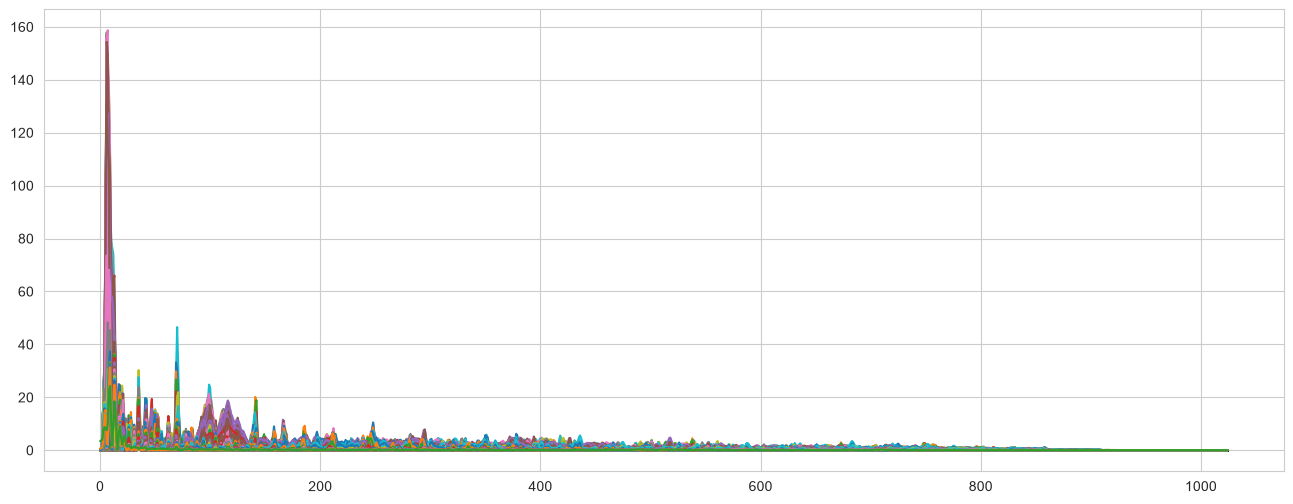

In [95]:
plt.figure(figsize = (16, 6))
plt.plot(D);

## Conversion to Spectrogram

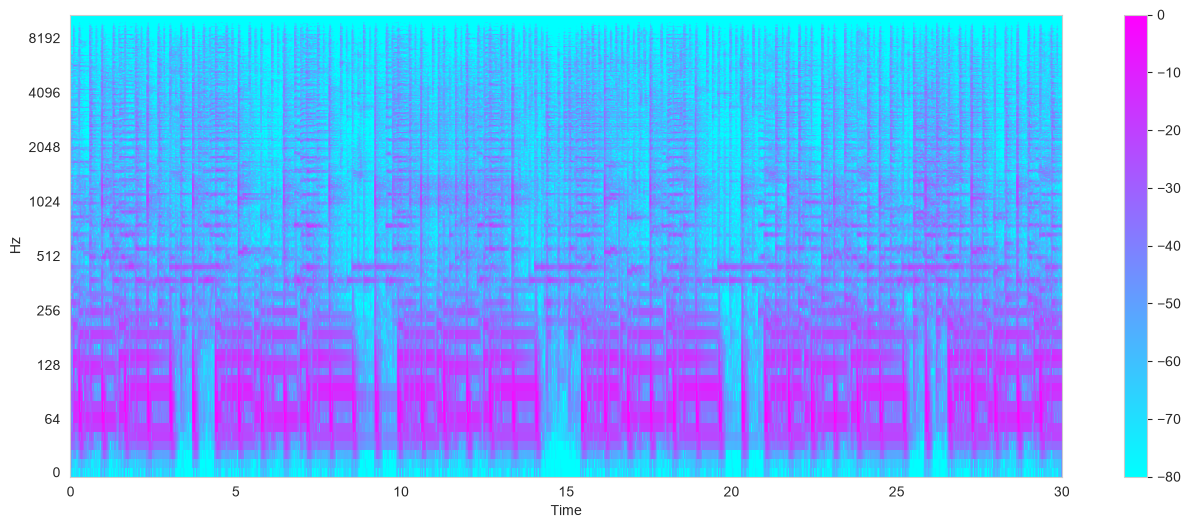

In [96]:
# Convert an amplitude spectrogram to Decibels-scaled spectrogram.
DB = librosa.amplitude_to_db(D, ref = np.max)

# Creating the Spectogram
plt.figure(figsize = (16, 6))
librosa.display.specshow(DB, sr = sr, hop_length = hop_length, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool')
plt.colorbar();

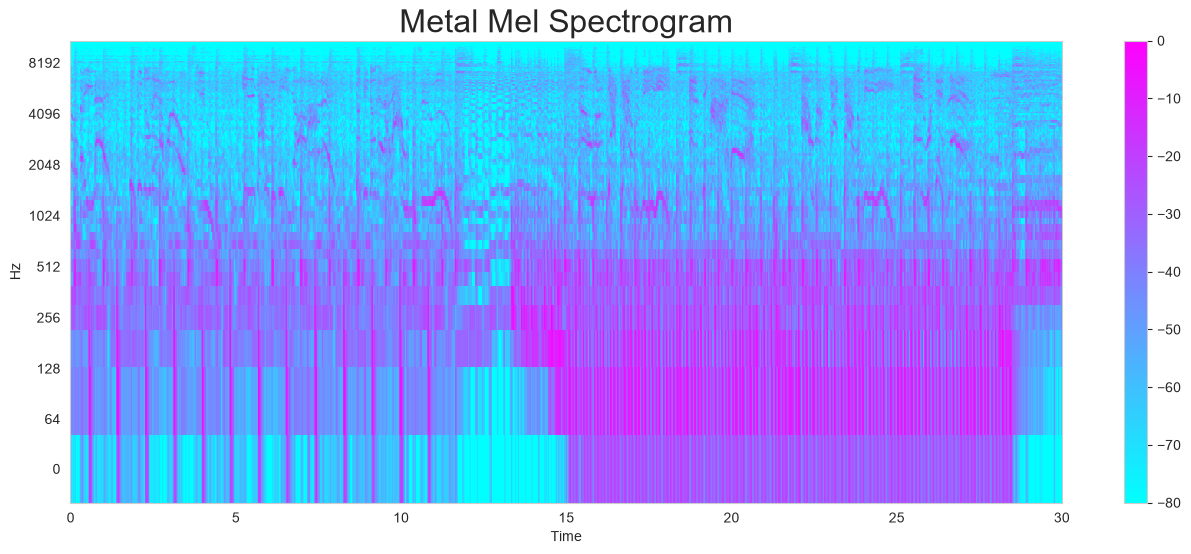

In [97]:
y, sr = librosa.load(f'{general_path}/genres/metal/metal.00036.wav')
y, _ = librosa.effects.trim(y)


S = librosa.feature.melspectrogram(y=y, sr=sr)
S_DB = librosa.amplitude_to_db(S, ref=np.max)
plt.figure(figsize = (16, 6))
librosa.display.specshow(S_DB, sr=sr, hop_length=hop_length, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool');
plt.colorbar();
plt.title("Metal Mel Spectrogram", fontsize = 23);

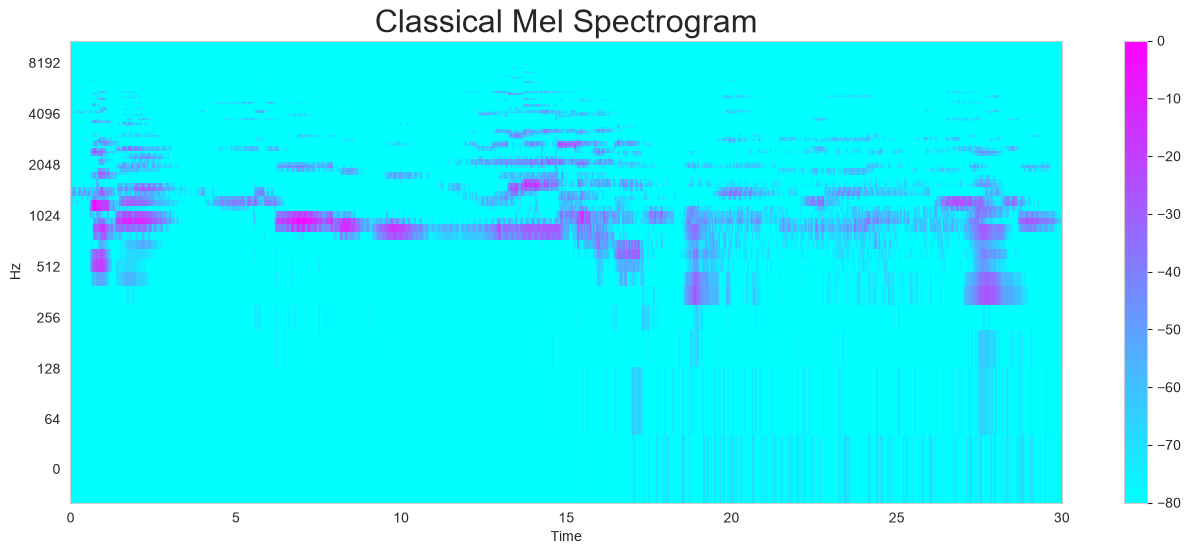

In [98]:
y, sr = librosa.load(f'{general_path}/genres/classical/classical.00036.wav')
y, _ = librosa.effects.trim(y)


S = librosa.feature.melspectrogram(y=y, sr=sr)
S_DB = librosa.amplitude_to_db(S, ref=np.max)
plt.figure(figsize = (16, 6))
librosa.display.specshow(S_DB, sr=sr, hop_length=hop_length, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool');
plt.colorbar();
plt.title("Classical Mel Spectrogram", fontsize = 23);

## Audio Features

#### Zero Crossing Rate

In [99]:
# Total zero_crossings in our 1 song
zero_crossings = librosa.zero_crossings(audio_file, pad=False)
print(sum(zero_crossings))

39232


#### Harmonics and Perceptual

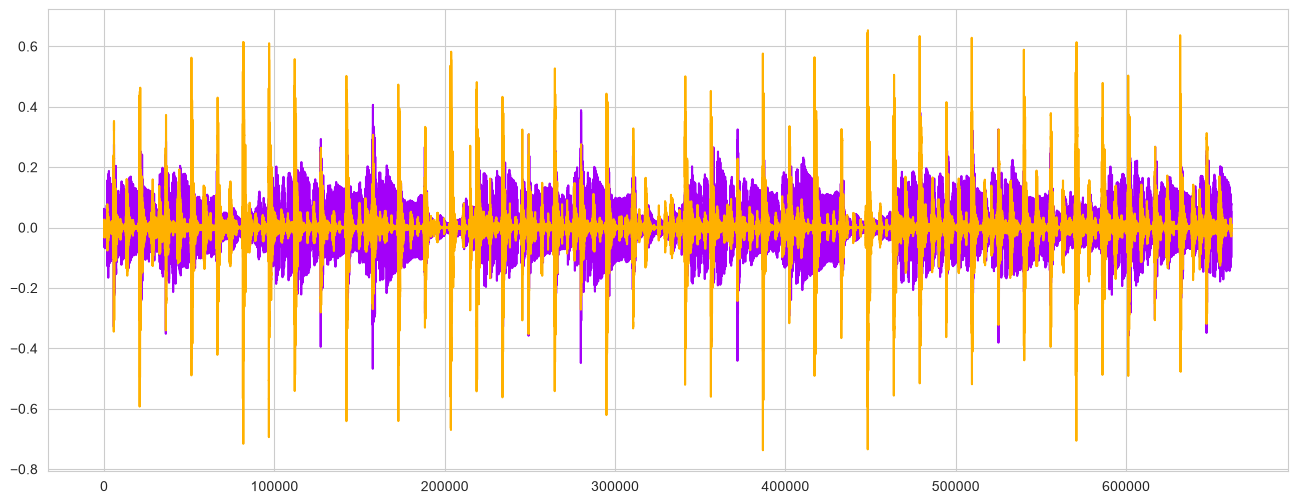

In [100]:
y_harm, y_perc = librosa.effects.hpss(audio_file)

plt.figure(figsize = (16, 6))
plt.plot(y_harm, color = '#A300F9');
plt.plot(y_perc, color = '#FFB100');

#### Tempo BPM

In [101]:
tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
tempo

array([107.66601562])

#### Spectral Centroid

In [102]:
# Calculate the Spectral Centroids
spectral_centroids = librosa.feature.spectral_centroid(y=audio_file, sr=sr)[0]

# Shape is a vector
print('Centroids:', spectral_centroids, '\n')
print('Shape of Spectral Centroids:', spectral_centroids.shape, '\n')

# Computing the time variable for visualization
frames = range(len(spectral_centroids))

# Converts frame counts to time (seconds)
t = librosa.frames_to_time(frames)

print('frames:', frames, '\n')
print('t:', t)

# Function that normalizes the Sound Data
def normalize(x, axis=0):
    return sklearn.preprocessing.minmax_scale(x, axis=axis)

Centroids: [1758.2948  1946.7424  2038.8114  ...  766.50415 1041.0774  1391.0515 ] 

Shape of Spectral Centroids: (1293,) 

frames: range(0, 1293) 

t: [0.00000000e+00 2.32199546e-02 4.64399093e-02 ... 2.99537415e+01
 2.99769615e+01 3.00001814e+01]


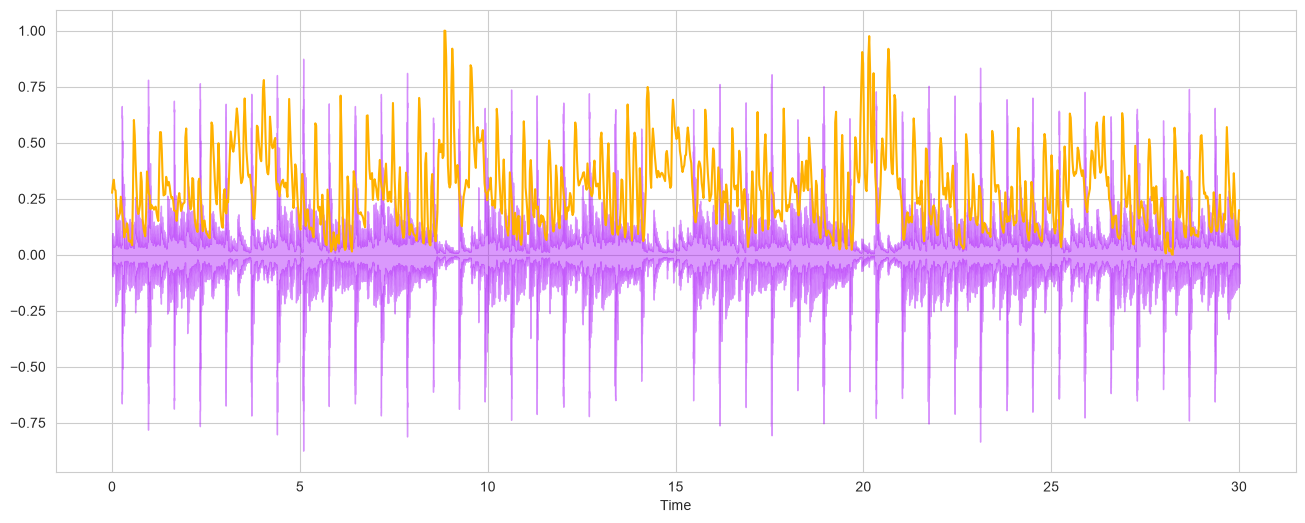

In [103]:
#Plotting the Spectral Centroid along the waveform
plt.figure(figsize = (16, 6))
librosa.display.waveshow(y=audio_file, sr=sr, alpha=0.4, color = '#A300F9');
plt.plot(t, normalize(spectral_centroids), color='#FFB100');

#### Spectral RollOff Vector

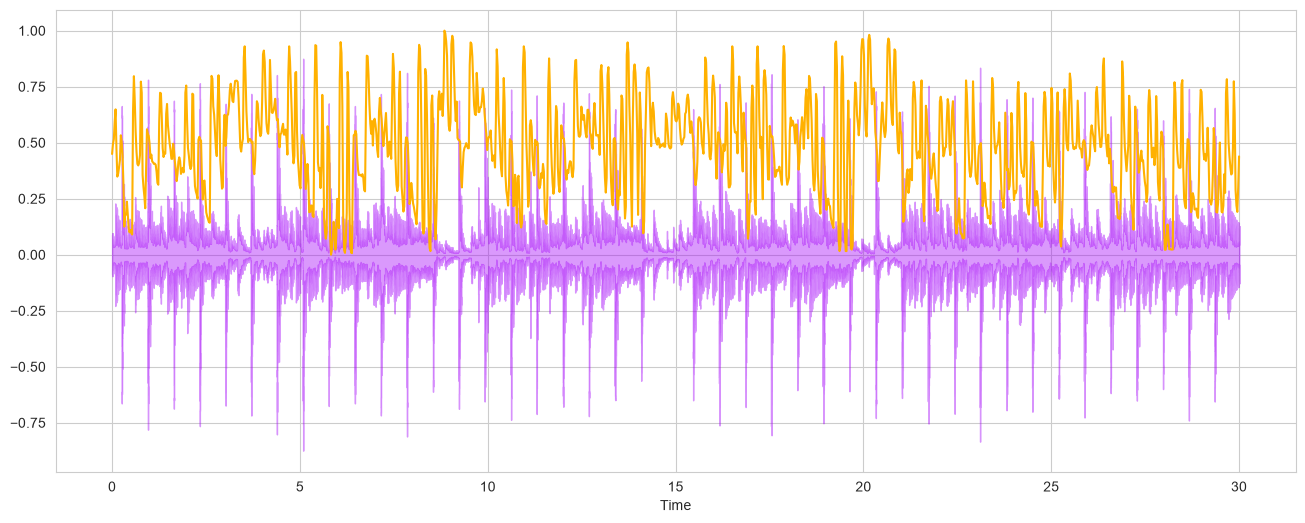

In [104]:
# Spectral RollOff Vector
spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)[0]

# The plot
plt.figure(figsize = (16, 6))
librosa.display.waveshow(audio_file, sr=sr, alpha=0.4, color = '#A300F9');
plt.plot(t, normalize(spectral_rolloff), color='#FFB100');

#### Mel-Frequency Cepstral Coefficients

mfccs shape: (20, 1293)


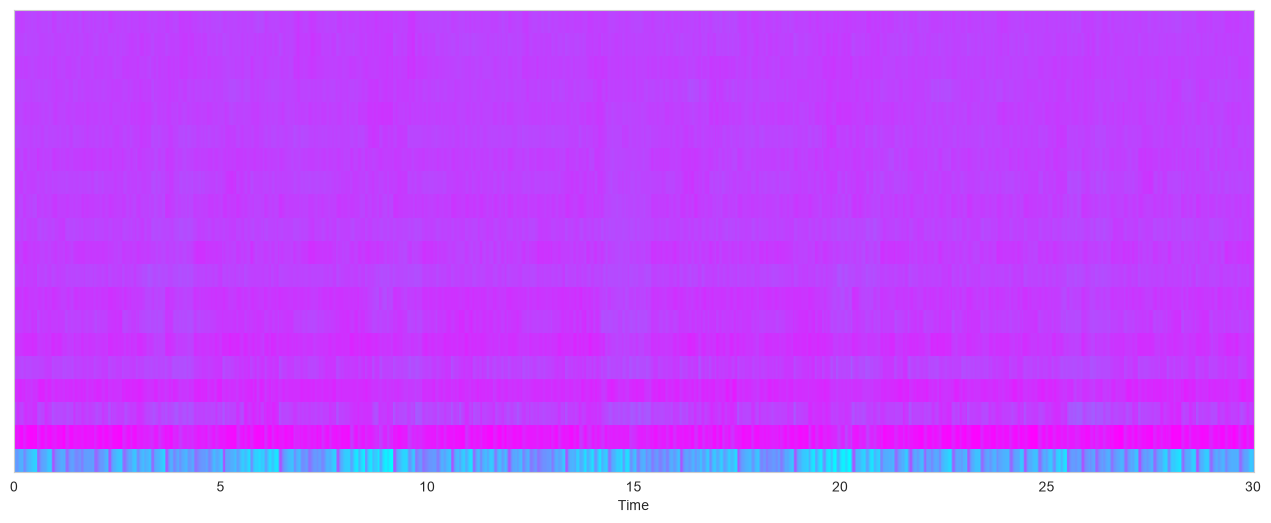

In [105]:
mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
print('mfccs shape:', mfccs.shape)

#Displaying  the MFCCs:
plt.figure(figsize = (16, 6))
librosa.display.specshow(mfccs, sr=sr, x_axis='time', cmap = 'cool');

Mean: -3.6878358e-09 

Var: 1.0


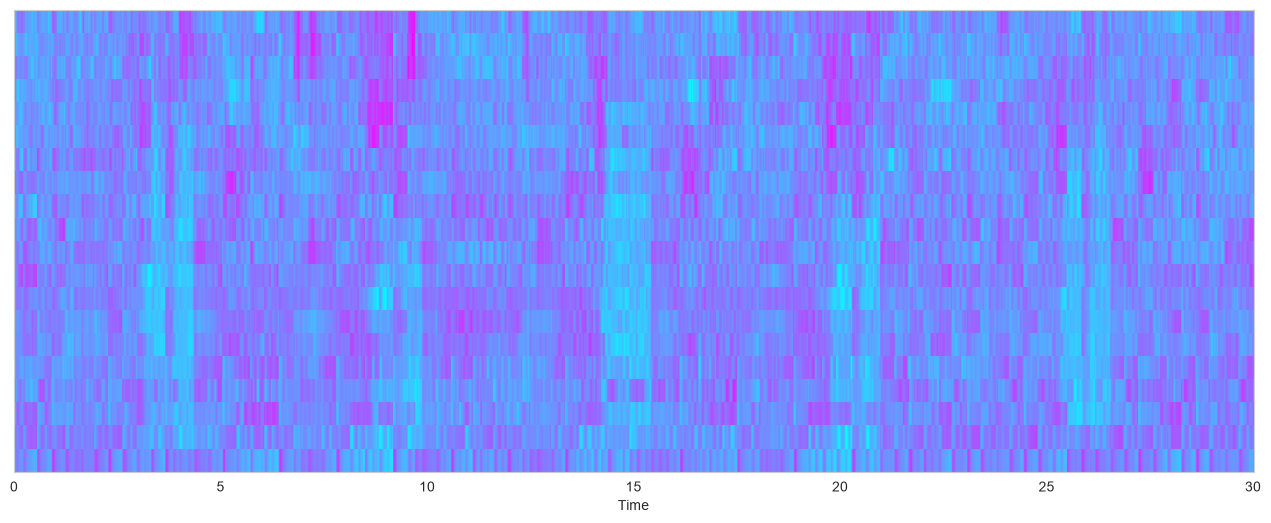

In [106]:
# Perform Feature Scaling
mfccs = sklearn.preprocessing.scale(mfccs, axis=1)
print('Mean:', mfccs.mean(), '\n')
print('Var:', mfccs.var())

plt.figure(figsize = (16, 6))
librosa.display.specshow(mfccs, sr=sr, x_axis='time', cmap = 'cool');

#### Chroma Frequencies

Chromogram shape: (12, 133)


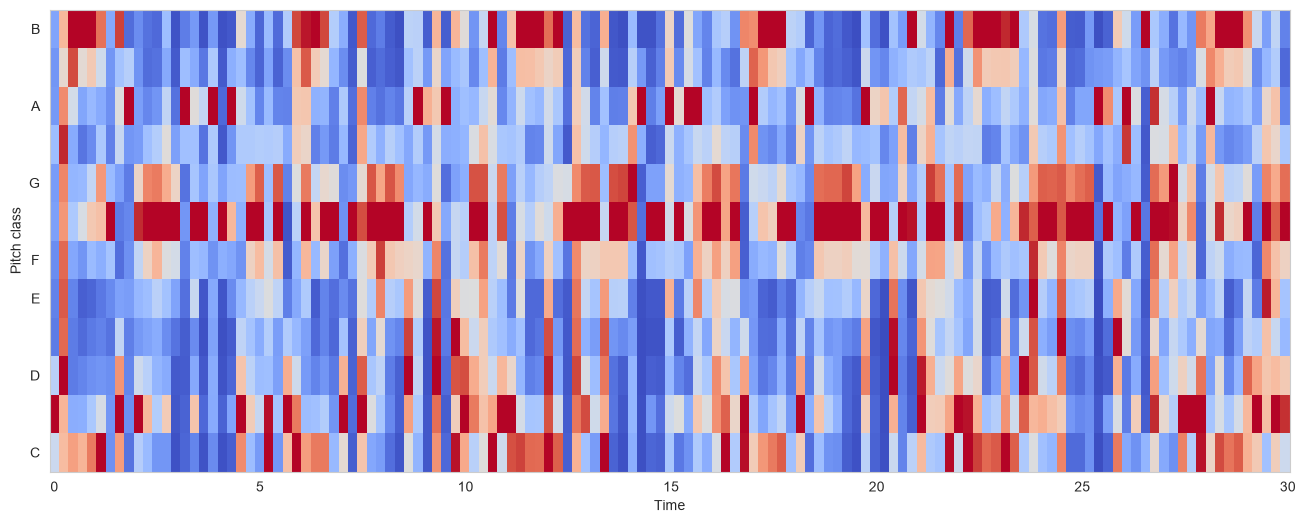

In [107]:
# Increase or decrease hop_length to change how granular you want your data to be
hop_length = 5000

# Chromogram
chromagram = librosa.feature.chroma_stft(y=audio_file, sr=sr, hop_length=hop_length)
print('Chromogram shape:', chromagram.shape)

plt.figure(figsize=(16, 6))
librosa.display.specshow(chromagram, x_axis='time', y_axis='chroma', hop_length=hop_length, cmap='coolwarm');

In [108]:
np.shape(audio_file)[0]

661794

# making dataframe

In [109]:
GTZAN_GENRES = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

In [111]:
GTZAN_GENRES = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


rows = []

for genre in GTZAN_GENRES:
    for i in range(100):
        if genre == "jazz" and i==54:
            continue
        number = "0000" + str(i) if i<10 else "000" + str(i)

        path = f'{genre}/{genre}.{number}.wav'
        
        y, sr = librosa.load(f'genres/{path}')

        audio_file, _ = librosa.effects.trim(y)

        n_fft = 2048 # FFT window size
        hop_length = 512 # number audio of frames between STFT columns (looks like a good default)

        zero_crossing_rate = librosa.feature.zero_crossing_rate(audio_file, pad=False)
        mean_zero_crossing_rate = np.mean(zero_crossing_rate)
        var_zero_crossings_rate = np.var(zero_crossing_rate)

        chroma_stft = librosa.feature.chroma_stft(y=audio_file,sr=sr)
        mean_chroma_stft = np.mean(chroma_stft)
        var_chroma_stft = np.var(chroma_stft)

        rms = librosa.feature.rms(y=audio_file)
        mean_rms = np.mean(rms)
        var_rms = np.var(rms)

        spectral_centroid = librosa.feature.spectral_centroid(y=audio_file, sr=sr)
        mean_spectral_centroid = np.mean(spectral_centroid)
        var_spectral_centroid = np.var(spectral_centroid)

        spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio_file, sr=sr)
        mean_spectral_bandwidth = np.mean(spectral_bandwidth)
        var_spectral_bandwidth = np.var(spectral_bandwidth)

        spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)
        mean_spectral_rolloff = np.mean(spectral_rolloff)
        var_spectral_rolloff = np.var(spectral_rolloff)

        harmonic, percussive = librosa.effects.hpss(audio_file)
        mean_harmonic = np.mean(harmonic)
        var_harmonic = np.var(harmonic)
        mean_percussive = np.mean(percussive)
        var_percussive = np.var(percussive)

        tempo = librosa.feature.tempo(y=audio_file, sr=sr)

        mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
        mfcc_means = np.mean(mfccs, axis=1)
        mfcc_vars = np.var(mfccs, axis=1)
        
        rows.append({
            'path': path,
            'length': (np.shape(y))[0],
            'sample_rate': sr,
            'chroma_stft_mean': mean_chroma_stft,
            'chroma_stft_var': var_chroma_stft,
            'rms_mean': mean_rms,
            'rms_var': var_rms,
            'spectral_centroid_mean': mean_spectral_centroid,
            'spectral_centroid_var': var_spectral_centroid,
            'spectral_bandwidth_mean': mean_spectral_bandwidth,
            'spectral_bandwidth_var': var_spectral_bandwidth,
            'spectral_rolloff_mean': mean_spectral_rolloff,
            'spectral_rolloff_var': var_spectral_rolloff,
            'zero_crossing_rate_mean': mean_zero_crossing_rate,
            'zero_crossing_rate_var': var_zero_crossings_rate,
            'harmony_mean': mean_harmonic,
            'harmony_var': var_harmonic,
            'percussive_mean': mean_percussive,
            'percussive_var': var_percussive,
            'tempo': tempo[0],
            'mfcc1_mean':mfcc_means[0],
            'mfcc1_var':mfcc_vars[0],
            'mfcc2_mean':mfcc_means[1],
            'mfcc2_var':mfcc_vars[1],
            'mfcc3_mean':mfcc_means[2],
            'mfcc3_var':mfcc_vars[2],
            'mfcc4_mean':mfcc_means[3],
            'mfcc4_var':mfcc_vars[3],
            'mfcc5_mean':mfcc_means[4],
            'mfcc5_var':mfcc_vars[4],
            'mfcc6_mean':mfcc_means[5],
            'mfcc6_var':mfcc_vars[5],
            'mfcc7_mean':mfcc_means[6],
            'mfcc7_var':mfcc_vars[6],
            'mfcc8_mean':mfcc_means[7],
            'mfcc8_var':mfcc_vars[7],
            'mfcc9_mean':mfcc_means[8],
            'mfcc9_var':mfcc_vars[8],
            'mfcc10_mean':mfcc_means[9],
            'mfcc10_var':mfcc_vars[9],
            'mfcc11_mean':mfcc_means[10],
            'mfcc11_var':mfcc_vars[10],
            'mfcc12_mean':mfcc_means[11],
            'mfcc12_var':mfcc_vars[11],
            'mfcc13_mean':mfcc_means[12],
            'mfcc13_var':mfcc_vars[12],
            'mfcc14_mean':mfcc_means[13],
            'mfcc14_var':mfcc_vars[13],
            'mfcc15_mean':mfcc_means[14],
            'mfcc15_var':mfcc_vars[14],
            'mfcc16_mean':mfcc_means[15],
            'mfcc16_var':mfcc_vars[15],
            'mfcc17_mean':mfcc_means[16],
            'mfcc17_var':mfcc_vars[16],
            'mfcc18_mean':mfcc_means[17],
            'mfcc18_var':mfcc_vars[17],
            'mfcc19_mean':mfcc_means[18],
            'mfcc19_var':mfcc_vars[18],
            'mfcc20_mean':mfcc_means[19],
            'mfcc20_var':mfcc_vars[19],
            'label': genre
        })

features_df = pd.DataFrame(rows)
features_df.head()


,path,length,sample_rate,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues/blues.00000.wav,661794,22050,0.350129,0.088772,0.130184,0.002828,1784.122559,129745.500000,2002.412598,...,52.424534,-1.687854,36.535866,-0.408730,41.603172,-2.302677,55.053654,1.222467,46.941349,blues
1,blues/blues.00001.wav,661794,22050,0.340849,0.094976,0.095908,0.002373,1530.261841,375915.500000,2038.987671,...,55.337963,-0.728403,60.231407,0.296872,48.133217,-0.282430,51.106014,0.530645,45.788700,blues
2,blues/blues.00002.wav,661794,22050,0.363538,0.085257,0.175473,0.002751,1552.832520,156471.000000,1747.754028,...,40.641678,-7.724840,47.629646,-1.819024,52.393597,-3.440458,46.643398,-2.238128,30.653151,blues
3,blues/blues.00003.wav,661794,22050,0.404854,0.093999,0.141040,0.006348,1070.153320,184366.015625,1596.422607,...,44.432903,-3.324069,50.218452,0.636311,37.325726,-0.615968,37.257774,-3.405046,31.965254,blues
4,blues/blues.00004.wav,661794,22050,0.308526,0.087843,0.091501,0.002305,1835.128540,343249.468750,1748.410645,...,85.995193,-5.451786,75.276741,-0.915952,53.633236,-4.408018,62.882492,-11.704385,55.190254,blues


In [112]:
features_df.to_csv('extracted-features/features.csv', index=False)

## Machine Learning Classification

In [113]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier, XGBRFClassifier
from xgboost import plot_tree, plot_importance

from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve
from sklearn import preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import RFE

In [114]:
data = pd.read_csv(f'{general_path}/extracted-features/features.csv')
data = data.iloc[0:, 1:] 
data.head()

,length,sample_rate,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,661794,22050,0.350129,0.088772,0.130184,0.002828,1784.1226,129745.50,2002.4126,85834.414,...,52.424534,-1.687854,36.535866,-0.408730,41.603172,-2.302677,55.053654,1.222467,46.941350,blues
1,661794,22050,0.340849,0.094976,0.095908,0.002373,1530.2618,375915.50,2038.9877,213905.120,...,55.337963,-0.728403,60.231407,0.296872,48.133217,-0.282430,51.106014,0.530645,45.788700,blues
2,661794,22050,0.363538,0.085257,0.175473,0.002751,1552.8325,156471.00,1747.7540,76295.414,...,40.641678,-7.724840,47.629646,-1.819024,52.393597,-3.440458,46.643400,-2.238128,30.653150,blues
3,661794,22050,0.404854,0.093999,0.141040,0.006348,1070.1533,184366.02,1596.4226,166551.840,...,44.432903,-3.324069,50.218452,0.636311,37.325726,-0.615968,37.257774,-3.405046,31.965254,blues
4,661794,22050,0.308526,0.087843,0.091501,0.002305,1835.1285,343249.47,1748.4106,88378.700,...,85.995190,-5.451786,75.276740,-0.915952,53.633236,-4.408018,62.882492,-11.704385,55.190254,blues


In [115]:
y = data['label'] # genre variable.
X = data.loc[:, data.columns != 'label'] #select all columns but not the labels

#### NORMALIZE X ####

# Normalize so everything is on the same scale. 

cols = X.columns
min_max_scaler = preprocessing.MinMaxScaler()
np_scaled = min_max_scaler.fit_transform(X)

# new data frame with the new scaled data. 
X = pd.DataFrame(np_scaled, columns = cols)

In [116]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [117]:
def model_assess(model, title = "Default", X_train=X_train, y_train=y_train, y_test=y_test):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    #print(confusion_matrix(y_test, preds))
    print('Accuracy', title, ':', round(accuracy_score(y_test, preds), 5), '\n')

In [118]:
# Versions with numerical labels [0,...9] for y-vals
# used for: Cross Gradient Border, Cross Gradient Border (Random Forest)
le = LabelEncoder()
y_train_numericallabels = le.fit_transform(y_train)
y_test_numericallabels = le.fit_transform(y_test)

# # Naive Bayes
# nb = GaussianNB()
# model_assess(nb, "Naive Bayes")

# # Stochastic Gradient Descent
# sgd = SGDClassifier(max_iter=5000, random_state=0)
# model_assess(sgd, "Stochastic Gradient Descent")

# # KNN
# knn = KNeighborsClassifier(n_neighbors=19)
# model_assess(knn, "KNN")

# # Decission trees
# tree = DecisionTreeClassifier()
# model_assess(tree, "Decision trees")

# # Random Forest
# rforest = RandomForestClassifier(n_estimators=1000, max_depth=10, random_state=0)
# model_assess(rforest, "Random Forest")

# # Support Vector Machine
# svm = SVC(decision_function_shape="ovo")
# model_assess(svm, "Support Vector Machine")

# # Logistic Regression
# lg = LogisticRegression(random_state=0, solver='lbfgs')
# model_assess(lg, "Logistic Regression")

# # Neural Nets
# nn = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(5000, 10), random_state=1)
# model_assess(nn, "Neural Nets")

# Cross Gradient Booster
xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05)
model_assess(xgb, "Cross Gradient Booster", y_train=y_train_numericallabels, y_test=y_test_numericallabels)

# Cross Gradient Booster (Random Forest)
xgbrf = XGBRFClassifier(objective= 'multi:softmax')
model_assess(xgbrf, "Cross Gradient Booster (Random Forest)", y_train=y_train_numericallabels, y_test=y_test_numericallabels)

Accuracy Cross Gradient Booster : 0.74667 

Accuracy Cross Gradient Booster (Random Forest) : 0.69 



Accuracy : 0.74667 



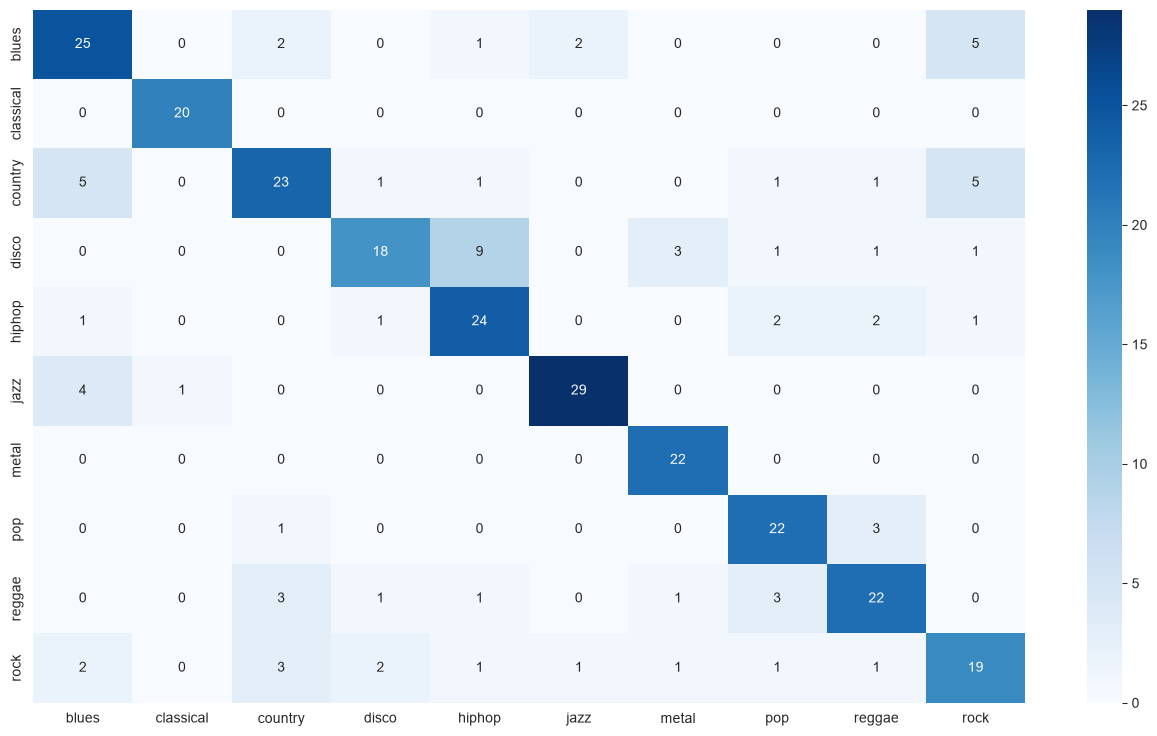

In [119]:
# Final model
xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05)
xgb.fit(X_train, y_train_numericallabels)


preds = xgb.predict(X_test)

print('Accuracy', ':', round(accuracy_score(y_test_numericallabels, preds), 5), '\n')

# Confusion Matrix
confusion_matr = confusion_matrix(y_test_numericallabels, preds) #normalize = 'true'
plt.figure(figsize = (16, 9))
sns.heatmap(confusion_matr, cmap="Blues", annot=True, 
            xticklabels = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"],
           yticklabels=["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]);
plt.savefig("conf matrix")

In [120]:
import eli5
from eli5.sklearn import PermutationImportance

perm = PermutationImportance(estimator=xgb, random_state=1)
perm.fit(X_test, y_test_numericallabels)

eli5.show_weights(estimator=perm, feature_names = X_test.columns.tolist())

Weight,Feature
0.1060 ± 0.0208,length
0.0673 ± 0.0268,percussive_var
0.0513 ± 0.0177,chroma_stft_mean
0.0460 ± 0.0236,chroma_stft_var
0.0213 ± 0.0150,harmony_mean
0.0187 ± 0.0205,rms_var
0.0133 ± 0.0060,spectral_rolloff_var
0.0127 ± 0.0065,mfcc4_mean
0.0120 ± 0.0090,mfcc16_var
0.0113 ± 0.0161,mfcc3_var


### CNN Version?

Ref: https://www.kaggle.com/code/imsparsh/gtzan-genre-classification-deep-learning-val-92-4

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
import sklearn.metrics as skm
import sklearn.model_selection as skms
import sklearn.preprocessing as skp
import random
import librosa, IPython
import librosa.display as lplt
seed = 12
np.random.seed(seed)

In [122]:
df = pd.read_csv(f'{general_path}/extracted-features/features.csv')
df.head()

,path,length,sample_rate,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues/blues.00000.wav,661794,22050,0.350129,0.088772,0.130184,0.002828,1784.1226,129745.50,2002.4126,...,52.424534,-1.687854,36.535866,-0.408730,41.603172,-2.302677,55.053654,1.222467,46.941350,blues
1,blues/blues.00001.wav,661794,22050,0.340849,0.094976,0.095908,0.002373,1530.2618,375915.50,2038.9877,...,55.337963,-0.728403,60.231407,0.296872,48.133217,-0.282430,51.106014,0.530645,45.788700,blues
2,blues/blues.00002.wav,661794,22050,0.363538,0.085257,0.175473,0.002751,1552.8325,156471.00,1747.7540,...,40.641678,-7.724840,47.629646,-1.819024,52.393597,-3.440458,46.643400,-2.238128,30.653150,blues
3,blues/blues.00003.wav,661794,22050,0.404854,0.093999,0.141040,0.006348,1070.1533,184366.02,1596.4226,...,44.432903,-3.324069,50.218452,0.636311,37.325726,-0.615968,37.257774,-3.405046,31.965254,blues
4,blues/blues.00004.wav,661794,22050,0.308526,0.087843,0.091501,0.002305,1835.1285,343249.47,1748.4106,...,85.995190,-5.451786,75.276740,-0.915952,53.633236,-4.408018,62.882492,-11.704385,55.190254,blues


In [123]:
print("Dataset has",df.shape)
print("Count of Positive and Negative samples")
df.label.value_counts().reset_index()

Dataset has (999, 61)
Count of Positive and Negative samples


,label,count
0,blues,100
1,classical,100
2,country,100
3,disco,100
4,hiphop,100
5,metal,100
6,pop,100
7,reggae,100
8,rock,100
9,jazz,99


In [124]:
# map labels to index
label_index = dict()
index_label = dict()
for i, x in enumerate(df.label.unique()):
    label_index[x] = i
    index_label[i] = x
print(label_index)
print(index_label)

{'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}
{0: 'blues', 1: 'classical', 2: 'country', 3: 'disco', 4: 'hiphop', 5: 'jazz', 6: 'metal', 7: 'pop', 8: 'reggae', 9: 'rock'}


In [125]:
seed = 42

# shuffle samples
df_shuffle = df.sample(frac=1, random_state=seed).reset_index(drop=True)

In [126]:
# remove irrelevant columns
df_shuffle.drop(['path', 'length'], axis=1, inplace=True)
df_y = df_shuffle.pop('label')
df_X = df_shuffle

# split into train dev and test
X_train, df_test_valid_X, y_train, df_test_valid_y = skms.train_test_split(df_X, df_y, train_size=0.7, random_state=seed, stratify=df_y)
X_dev, X_test, y_dev, y_test = skms.train_test_split(df_test_valid_X, df_test_valid_y, train_size=0.66, random_state=seed, stratify=df_test_valid_y)

# Versions with numerical labels [0,...9] for y-vals
# used for: Cross Gradient Border, Cross Gradient Border (Random Forest)
le = LabelEncoder()
y_train_numericallabels = le.fit_transform(y_train)
y_dev_numericallabels = le.fit_transform(y_dev)
y_test_numericallabels = le.fit_transform(y_test)

In [127]:
print(f"Train set has {X_train.shape[0]} records out of {len(df_shuffle)} which is {round(X_train.shape[0]/len(df_shuffle)*100)}%")
print(f"Dev set has {X_dev.shape[0]} records out of {len(df_shuffle)} which is {round(X_dev.shape[0]/len(df_shuffle)*100)}%")
print(f"Test set has {X_test.shape[0]} records out of {len(df_shuffle)} which is {round(X_test.shape[0]/len(df_shuffle)*100)}%")

Train set has 699 records out of 999 which is 70%
Dev set has 198 records out of 999 which is 20%
Test set has 102 records out of 999 which is 10%


In [128]:
# print(y_train.value_counts()[0]/y_train.shape[0]*100)
# print(y_dev.value_counts()[0]/y_dev.shape[0]*100)
# print(y_test.value_counts()[0]/y_test.shape[0]*100)

In [129]:
scaler = skp.StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_dev = pd.DataFrame(scaler.transform(X_dev), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_train.columns)

In [130]:
import tensorflow as tf
print("TF version:-", tf.__version__)
import keras as k
tf.random.set_seed(seed)

TF version:- 2.22.0-rc1


In [131]:
ACCURACY_THRESHOLD = 0.94

class myCallback(k.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if(logs.get('val_accuracy') > ACCURACY_THRESHOLD):
            print("\n\nStopping training as we have reached %2.2f%% accuracy!" %(ACCURACY_THRESHOLD*100))   
            self.model.stop_training = True

def trainModel(model, epochs, optimizer):
    batch_size = 128
    callback = myCallback()
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy']
    )
    return model.fit(X_train, y_train_numericallabels, validation_data=(X_dev, y_dev_numericallabels), epochs=epochs, 
                     batch_size=batch_size, callbacks=[callback]) # the error is here

def plotHistory(history):
    print("Max. Validation Accuracy",max(history.history["val_accuracy"]))
    pd.DataFrame(history.history).plot(figsize=(12,6))
    plt.show()

def generateConfusionMatrix(model, filename="model"):
    preds = model.predict(X_test)
    preds = np.argmax(preds, axis=1)
    print('Accuracy', ':', round(accuracy_score(y_test_numericallabels, preds), 5), '\n')
    confusion_matr = confusion_matrix(y_test_numericallabels, preds) #normalize = 'true'
    plt.figure(figsize = (16, 9))
    sns.heatmap(confusion_matr, cmap="Blues", annot=True, 
        xticklabels = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"],
        yticklabels=["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]);
    plt.savefig(f"conf matrix {filename}")

In [132]:
model_1 = k.models.Sequential([
    k.layers.Dense(256, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dense(128, activation='relu'),
    k.layers.Dense(64, activation='relu'),
    k.layers.Dense(10, activation='softmax'),
])
print(model_1.summary())
model_1_history = trainModel(model=model_1, epochs=70, optimizer='adam') # the error is here

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_28 (Dense)                │ (None, 256)            │        15,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,906 (222.29 KB)

 Trainable params: 56,906 (222.29 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 0.2389 - loss: 2.1849 - val_accuracy: 0.4040 - val_loss: 1.9372
Epoch 2/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4664 - loss: 1.7818 - val_accuracy: 0.4646 - val_loss: 1.6561
Epoch 3/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5608 - loss: 1.4772 - val_accuracy: 0.5101 - val_loss: 1.4292
Epoch 4/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6352 - loss: 1.2325 - val_accuracy: 0.5556 - val_loss: 1.2650
Epoch 5/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6910 - loss: 1.0429 - val_accuracy: 0.5859 - val_loss: 1.1543
Epoch 6/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7411 - loss: 0.8934 - val_accuracy: 0.6010 - val_loss: 1.0937
Epoch 7/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7711 - loss: 0.7695 - val_accuracy: 0.6162 - val_loss: 1.0421
Epoch 8/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8069 - loss: 0.6644 - val_accuracy: 0.6414 - val_loss: 1

Max. Validation Accuracy 0.7272727489471436


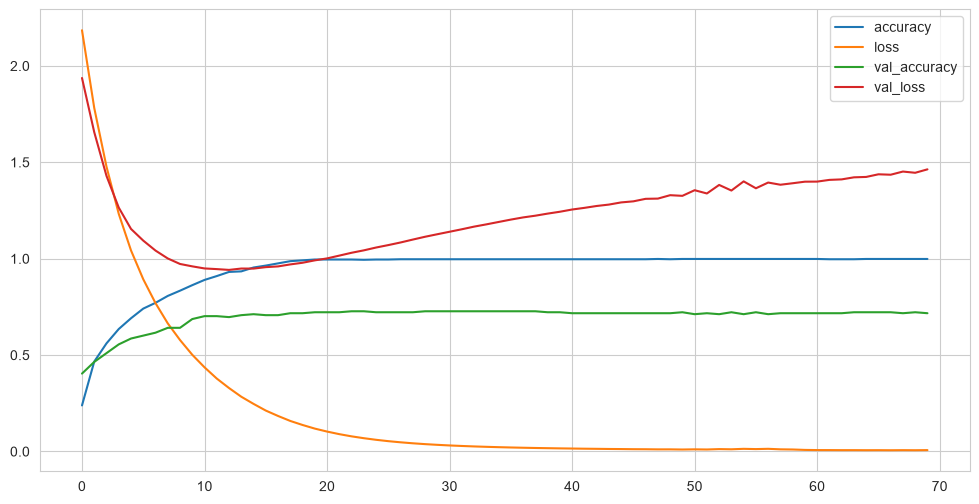

In [133]:
plotHistory(model_1_history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Accuracy : 0.7549 



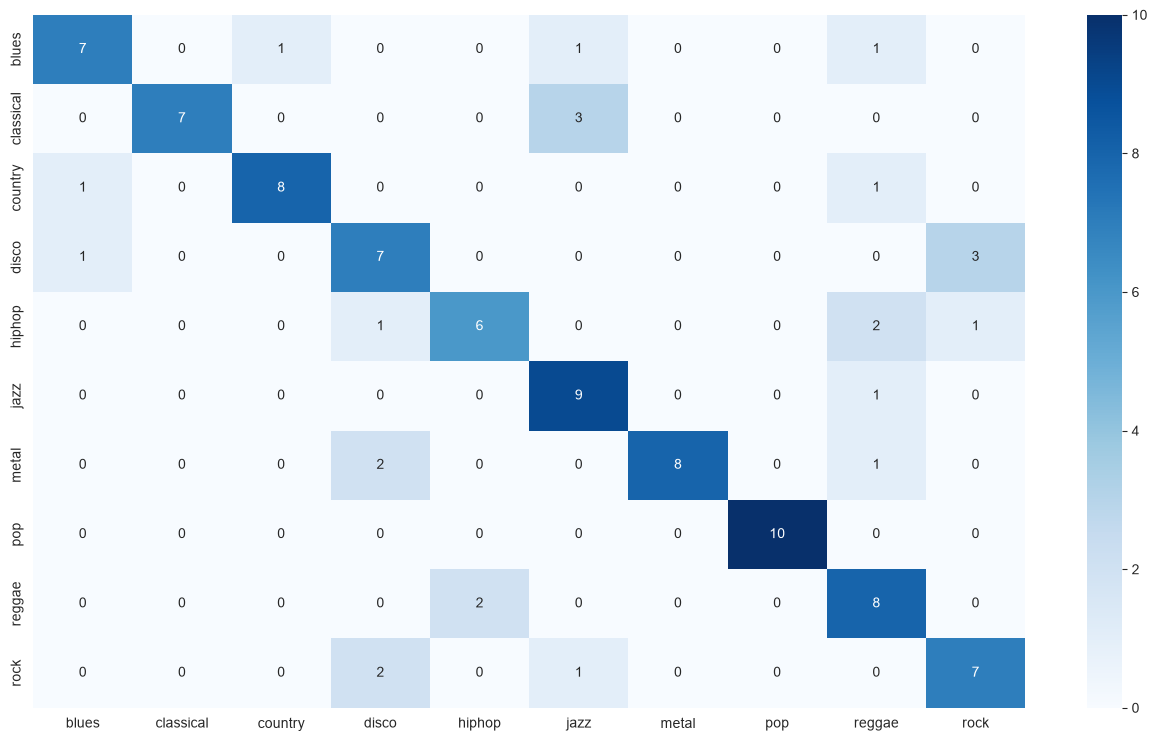

In [134]:
generateConfusionMatrix(model=model_1,filename="model1")

In [135]:
model_2 = k.models.Sequential([
    k.layers.Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dropout(0.2),
    
    k.layers.Dense(256, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(128, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(64, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(10, activation='softmax'),
])
print(model_2.summary())
model_2_history = trainModel(model=model_2, epochs=100, optimizer='adam')

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_32 (Dense)                │ (None, 512)            │        30,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,338 (794.29 KB)

 Trainable params: 203,338 (794.29 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.2289 - loss: 2.2018 - val_accuracy: 0.3889 - val_loss: 1.9592
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3805 - loss: 1.9158 - val_accuracy: 0.4091 - val_loss: 1.6548
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4363 - loss: 1.6383 - val_accuracy: 0.4899 - val_loss: 1.4383
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4821 - loss: 1.4372 - val_accuracy: 0.5101 - val_loss: 1.3107
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5465 - loss: 1.3196 - val_accuracy: 0.5404 - val_loss: 1.2096
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5951 - loss: 1.1819 - val_accuracy: 0.5909 - val_loss: 1.1356
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6280 - loss: 1.0784 - val_accuracy: 0.6212 - val_loss: 1.0533
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6466 - loss: 0.9948 - val_accuracy: 0.6364 - val

Max. Validation Accuracy 0.7626262903213501


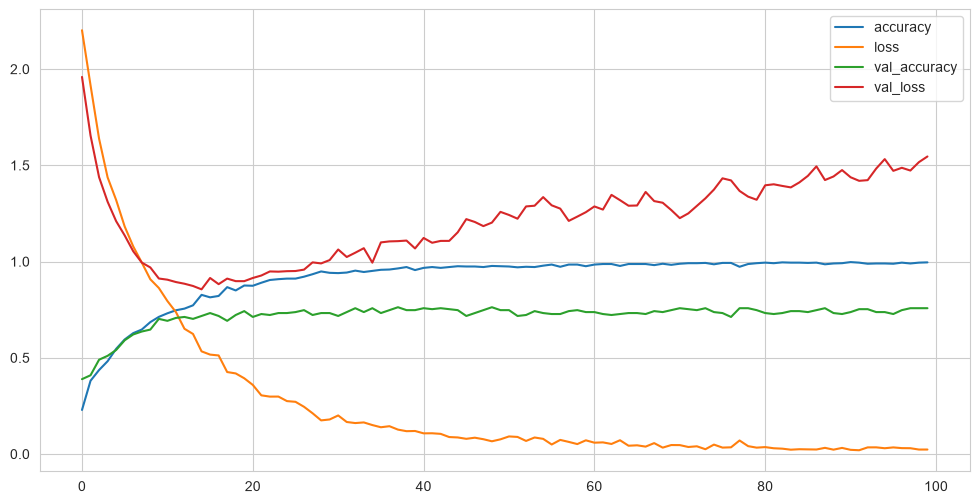

In [136]:
plotHistory(model_2_history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Accuracy : 0.76471 



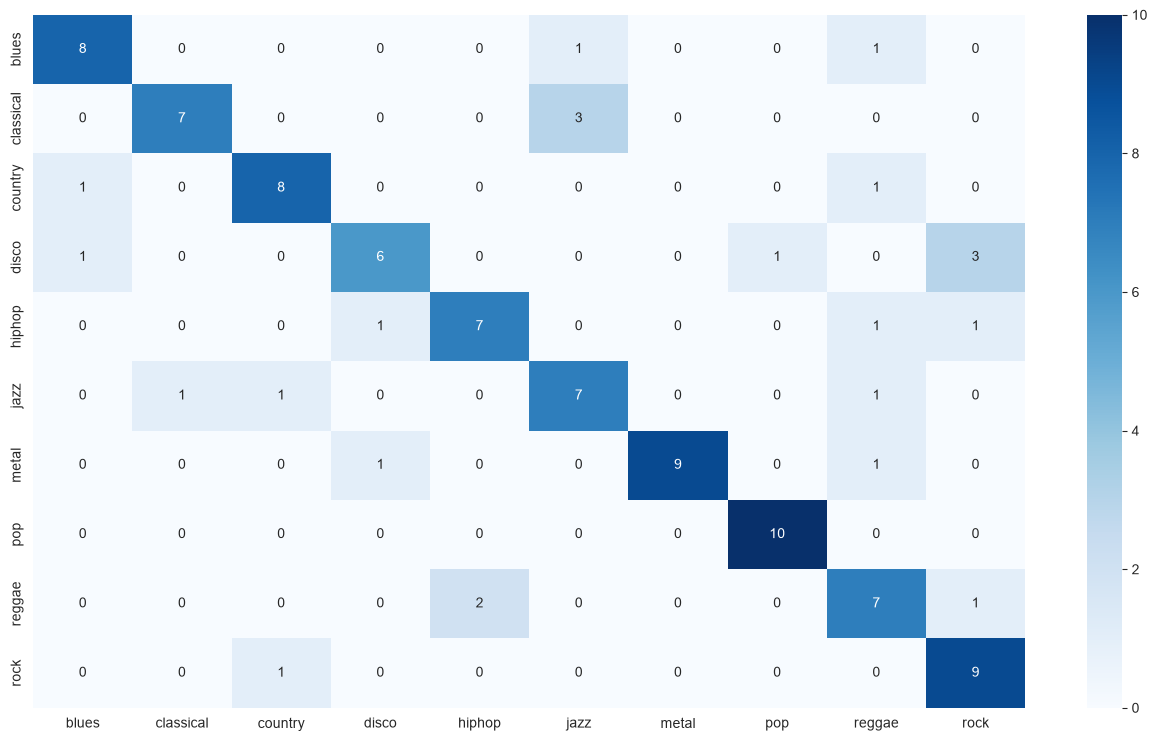

In [137]:
generateConfusionMatrix(model=model_2,filename="model2")

In [138]:
model_3 = k.models.Sequential([
    k.layers.Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dropout(0.2),
    
    k.layers.Dense(256, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(128, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(64, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(10, activation='softmax'),
])
print(model_3.summary())
model_3_history = trainModel(model=model_3, epochs=700, optimizer='sgd')

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_37 (Dense)                │ (None, 512)            │        30,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,338 (794.29 KB)

 Trainable params: 203,338 (794.29 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.0873 - loss: 2.3922 - val_accuracy: 0.1010 - val_loss: 2.3348
Epoch 2/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0901 - loss: 2.3600 - val_accuracy: 0.1010 - val_loss: 2.3110
Epoch 3/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1059 - loss: 2.3254 - val_accuracy: 0.1263 - val_loss: 2.2907
Epoch 4/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.1431 - loss: 2.3032 - val_accuracy: 0.1717 - val_loss: 2.2716
Epoch 5/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1474 - loss: 2.2863 - val_accuracy: 0.2071 - val_loss: 2.2540
Epoch 6/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1459 - loss: 2.2660 - val_accuracy: 0.2323 - val_loss: 2.2373
Epoch 7/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1602 - loss: 2.2535 - val_accuracy: 0.2778 - val_loss: 2.2209
Epoch 8/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1874 - loss: 2.2440 - val_accuracy: 0.2929 - val

Max. Validation Accuracy 0.7575757503509521


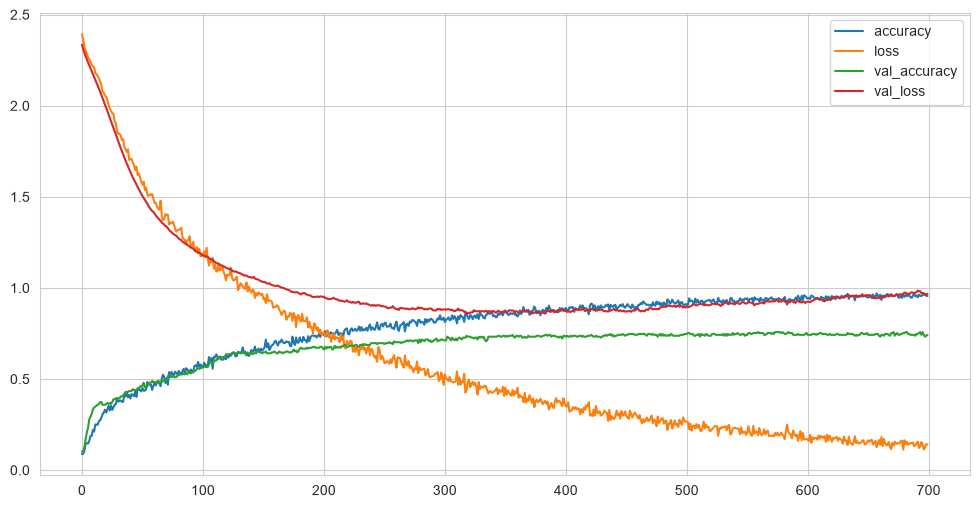

In [139]:
plotHistory(model_3_history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Accuracy : 0.81373 



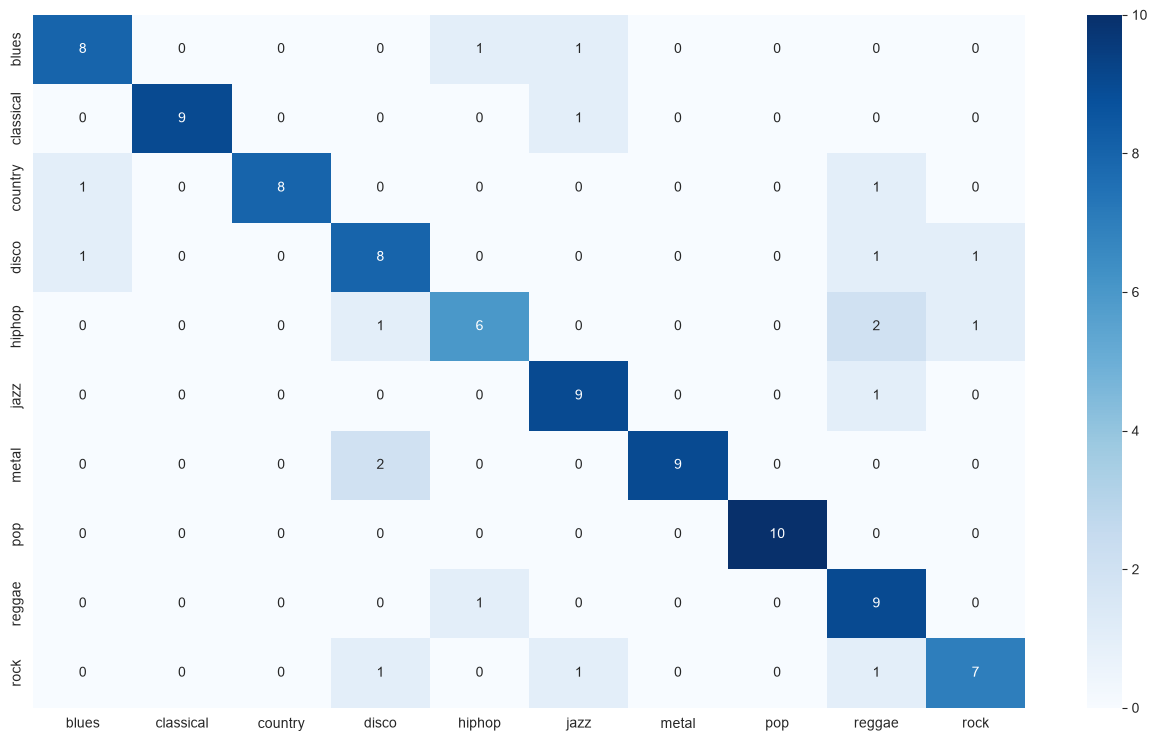

In [140]:
generateConfusionMatrix(model=model_3,filename="model3")

In [141]:
model_4 = k.models.Sequential([
    k.layers.Dense(1024, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dropout(0.3),
    
    k.layers.Dense(512, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(256, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(128, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(64, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(10, activation='softmax'),
])
print(model_4.summary())
model_4_history = trainModel(model=model_4, epochs=500, optimizer='rmsprop')

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 1024)           │        60,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 758,346 (2.89 MB)

 Trainable params: 758,346 (2.89 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.1602 - loss: 2.1948 - val_accuracy: 0.3081 - val_loss: 1.8454
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2990 - loss: 1.9000 - val_accuracy: 0.3737 - val_loss: 1.6533
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3705 - loss: 1.7346 - val_accuracy: 0.4444 - val_loss: 1.5573
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4177 - loss: 1.5958 - val_accuracy: 0.5000 - val_loss: 1.3987
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4492 - loss: 1.5237 - val_accuracy: 0.4848 - val_loss: 1.4119
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4964 - loss: 1.3840 - val_accuracy: 0.5253 - val_loss: 1.2561
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5222 - loss: 1.3465 - val_accuracy: 0.5909 - val_loss: 1.2587
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5665 - loss: 1.2421 - val_accuracy: 0.6313 - val

Max. Validation Accuracy 0.7777777910232544


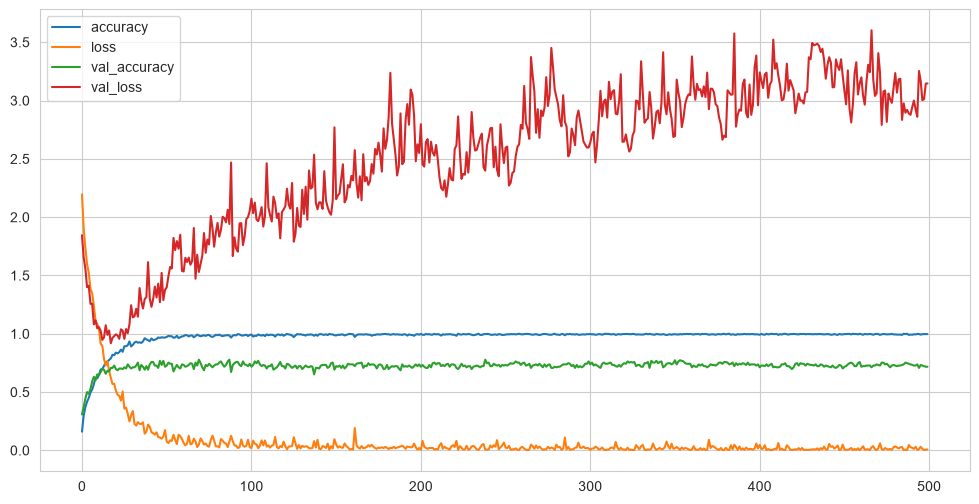

In [142]:
plotHistory(model_4_history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Accuracy : 0.80392 



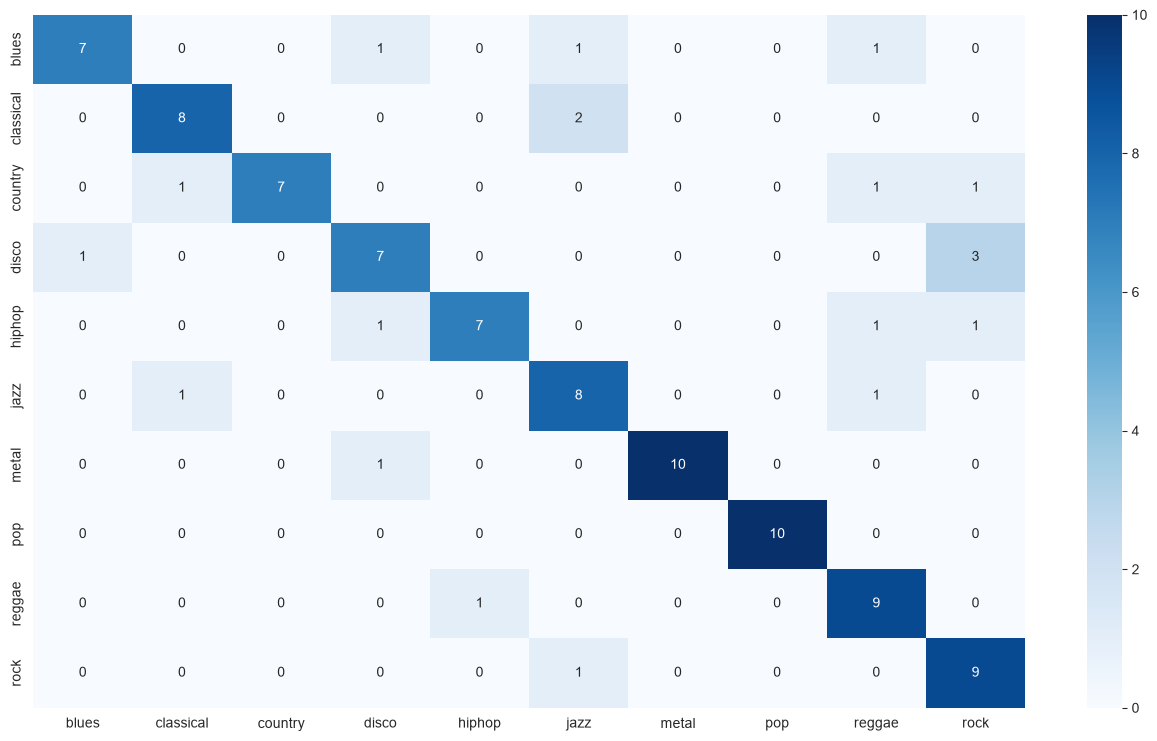

In [143]:
generateConfusionMatrix(model=model_4,filename="model4")

In [ ]:
def extractFeatures(file):
    path = file
    y, sr = librosa.load(path)  
    audio_file, _ = librosa.effects.trim(y)
    
    zero_crossing_rate = librosa.feature.zero_crossing_rate(audio_file, pad=False)
    mean_zero_crossing_rate = np.mean(zero_crossing_rate)
    var_zero_crossings_rate = np.var(zero_crossing_rate)
    
    chroma_stft = librosa.feature.chroma_stft(y=audio_file,sr=sr)
    mean_chroma_stft = np.mean(chroma_stft)
    var_chroma_stft = np.var(chroma_stft)
    
    rms = librosa.feature.rms(y=audio_file)
    mean_rms = np.mean(rms)
    var_rms = np.var(rms)
    
    spectral_centroid = librosa.feature.spectral_centroid(y=audio_file, sr=sr)
    mean_spectral_centroid = np.mean(spectral_centroid)
    var_spectral_centroid = np.var(spectral_centroid)
    
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio_file, sr=sr)
    mean_spectral_bandwidth = np.mean(spectral_bandwidth)
    var_spectral_bandwidth = np.var(spectral_bandwidth)
    
    spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)
    mean_spectral_rolloff = np.mean(spectral_rolloff)
    var_spectral_rolloff = np.var(spectral_rolloff)
    
    harmonic, percussive = librosa.effects.hpss(audio_file)
    mean_harmonic = np.mean(harmonic)
    var_harmonic = np.var(harmonic)
    mean_percussive = np.mean(percussive)
    var_percussive = np.var(percussive)

    tempo = librosa.feature.tempo(y=audio_file, sr=sr)

    mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
    mfcc_means = np.mean(mfccs, axis=1)
    mfcc_vars = np.var(mfccs, axis=1)
    rows = []
    rows.append({
        'sample_rate': sr,
        'chroma_stft_mean': mean_chroma_stft,
        'chroma_stft_var': var_chroma_stft,
        'rms_mean': mean_rms,
        'rms_var': var_rms,
        'spectral_centroid_mean': mean_spectral_centroid,
        'spectral_centroid_var': var_spectral_centroid,
        'spectral_bandwidth_mean': mean_spectral_bandwidth,
        'spectral_bandwidth_var': var_spectral_bandwidth,
        'spectral_rolloff_mean': mean_spectral_rolloff,
        'spectral_rolloff_var': var_spectral_rolloff,
        'zero_crossing_rate_mean': mean_zero_crossing_rate,
        'zero_crossing_rate_var': var_zero_crossings_rate,
        'harmony_mean': mean_harmonic,
        'harmony_var': var_harmonic,
        'percussive_mean': mean_percussive,
        'percussive_var': var_percussive,
        'tempo': tempo[0],
        'mfcc1_mean':mfcc_means[0],
        'mfcc1_var':mfcc_vars[0],
        'mfcc2_mean':mfcc_means[1],
        'mfcc2_var':mfcc_vars[1],
        'mfcc3_mean':mfcc_means[2],
        'mfcc3_var':mfcc_vars[2],
        'mfcc4_mean':mfcc_means[3],
        'mfcc4_var':mfcc_vars[3],
        'mfcc5_mean':mfcc_means[4],
        'mfcc5_var':mfcc_vars[4],
        'mfcc6_mean':mfcc_means[5],
        'mfcc6_var':mfcc_vars[5],
        'mfcc7_mean':mfcc_means[6],
        'mfcc7_var':mfcc_vars[6],
        'mfcc8_mean':mfcc_means[7],
        'mfcc8_var':mfcc_vars[7],
        'mfcc9_mean':mfcc_means[8],
        'mfcc9_var':mfcc_vars[8],
        'mfcc10_mean':mfcc_means[9],
        'mfcc10_var':mfcc_vars[9],
        'mfcc11_mean':mfcc_means[10],
        'mfcc11_var':mfcc_vars[10],
        'mfcc12_mean':mfcc_means[11],
        'mfcc12_var':mfcc_vars[11],
        'mfcc13_mean':mfcc_means[12],
        'mfcc13_var':mfcc_vars[12],
        'mfcc14_mean':mfcc_means[13],
        'mfcc14_var':mfcc_vars[13],
        'mfcc15_mean':mfcc_means[14],
        'mfcc15_var':mfcc_vars[14],
        'mfcc16_mean':mfcc_means[15],
        'mfcc16_var':mfcc_vars[15],
        'mfcc17_mean':mfcc_means[16],
        'mfcc17_var':mfcc_vars[16],
        'mfcc18_mean':mfcc_means[17],
        'mfcc18_var':mfcc_vars[17],
        'mfcc19_mean':mfcc_means[18],
        'mfcc19_var':mfcc_vars[18],
        'mfcc20_mean':mfcc_means[19],
        'mfcc20_var':mfcc_vars[19],
    })
    to_return = pd.DataFrame(rows)
    to_return = pd.DataFrame(scaler.transform(to_return), columns=X_train.columns)
    return to_return

def testSample(model, file):
    predictions = model.predict(extractFeatures(file))
    predicted_class = np.argmax(predictions, axis=1)[0]
    predicted_genre = GTZAN_GENRES[predicted_class]
    confidence = predictions[0][predicted_class] * 100
    return predicted_genre, confidence

In [ ]:
def displaySpectogram(filename):

    n_fft = 2048 # FFT window size
    hop_length = 512 # number audio of frames between STFT columns (looks like a good default)

    y, sr = librosa.load(filename)  
    audio_file, _ = librosa.effects.trim(y)

    plt.figure(figsize = (16, 6))

    #Fourier Transform
    D = np.abs(librosa.stft(audio_file, n_fft = n_fft, hop_length = hop_length))
    plt.plot(D);
    plt.title(f"{filename} STFT", fontsize = 23);

    #Spectogram
    DB = librosa.amplitude_to_db(D, ref = np.max)
    plt.figure(figsize = (16, 6))
    librosa.display.specshow(DB, sr = sr, hop_length = hop_length, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool')
    plt.colorbar();
    plt.title(f"{filename} Spectrogram", fontsize = 23);

    #Mel Spectogram
    S = librosa.feature.melspectrogram(y=y, sr=sr)
    S_DB = librosa.amplitude_to_db(S, ref=np.max)
    plt.figure(figsize = (16, 6))
    librosa.display.specshow(S_DB, sr=sr, hop_length=hop_length, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool');
    plt.colorbar();
    plt.title(f"{filename} Mel Spectrogram", fontsize = 23);

def normalize(x, axis=0):
    return sklearn.preprocessing.minmax_scale(x, axis=axis)

def displayFeatures(filename):
    y, sr = librosa.load(filename)  
    audio_file, _ = librosa.effects.trim(y)
    y_harm, y_perc = librosa.effects.hpss(audio_file)

    plt.figure(figsize = (16, 6))
    plt.plot(y_harm, color = '#A300F9');
    plt.plot(y_perc, color = '#FFB100');
    plt.title(f"{filename} Harmonics and Perceptual", fontsize = 23);

    #Plotting the Spectral Centroid along the waveform
    spectral_centroids = librosa.feature.spectral_centroid(y=audio_file, sr=sr)[0]
    frames = range(len(spectral_centroids))
    t = librosa.frames_to_time(frames)

    plt.figure(figsize = (16, 6))
    librosa.display.waveshow(y=audio_file, sr=sr, alpha=0.4, color = '#A300F9');
    plt.plot(t, normalize(spectral_centroids), color='#FFB100');
    plt.title(f"{filename} Spectral Centroid", fontsize = 23);

    # Spectral Bandwidth Vector
    spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)[0]

    plt.figure(figsize = (16, 6))
    librosa.display.waveshow(audio_file, sr=sr, alpha=0.4, color = '#A300F9');
    plt.plot(t, normalize(spectral_rolloff), color='#FFB100');
    plt.title(f"{filename} Spectral RollOff", fontsize = 23);

    # Spectral RollOff Vector
    spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)[0]

    plt.figure(figsize = (16, 6))
    librosa.display.waveshow(audio_file, sr=sr, alpha=0.4, color = '#A300F9');
    plt.plot(t, normalize(spectral_rolloff), color='#FFB100');
    plt.title(f"{filename} Spectral RollOff", fontsize = 23);


    #MFCC
    mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
    mfccs = sklearn.preprocessing.scale(mfccs, axis=1)

    #Displaying  the MFCCs:
    plt.figure(figsize = (16, 6))
    librosa.display.specshow(mfccs, sr=sr, x_axis='time', cmap = 'cool');
    plt.title(f"{filename} MFCC", fontsize = 23);

    hop_length = 5000

    # Chromogram
    chromagram = librosa.feature.chroma_stft(y=audio_file, sr=sr, hop_length=hop_length)

    plt.figure(figsize=(16, 6))
    librosa.display.specshow(chromagram, x_axis='time', y_axis='chroma', hop_length=hop_length, cmap='coolwarm');
    plt.title(f"{filename} Chroma Frequencies", fontsize = 23);


In [191]:

genre, confidence = testSample(model_1,'beethoven.wav')

print("Predicted Genre:", genre)
print("Confidence:", f"{confidence:.5f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
[8.0504471e-08 9.9980932e-01 1.1193689e-10 4.7255070e-15 5.2132731e-21
 1.9059914e-04 3.2269133e-19 1.7868634e-11 1.1442442e-12 1.8002465e-18]
Predicted Genre: classical
Confidence: 99.98093%


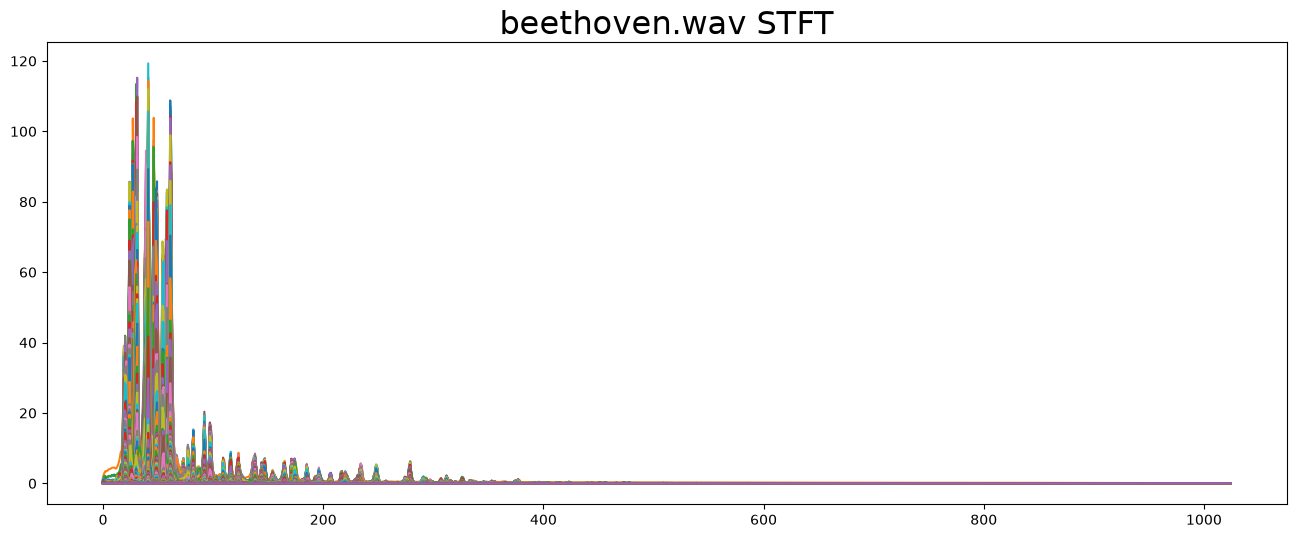

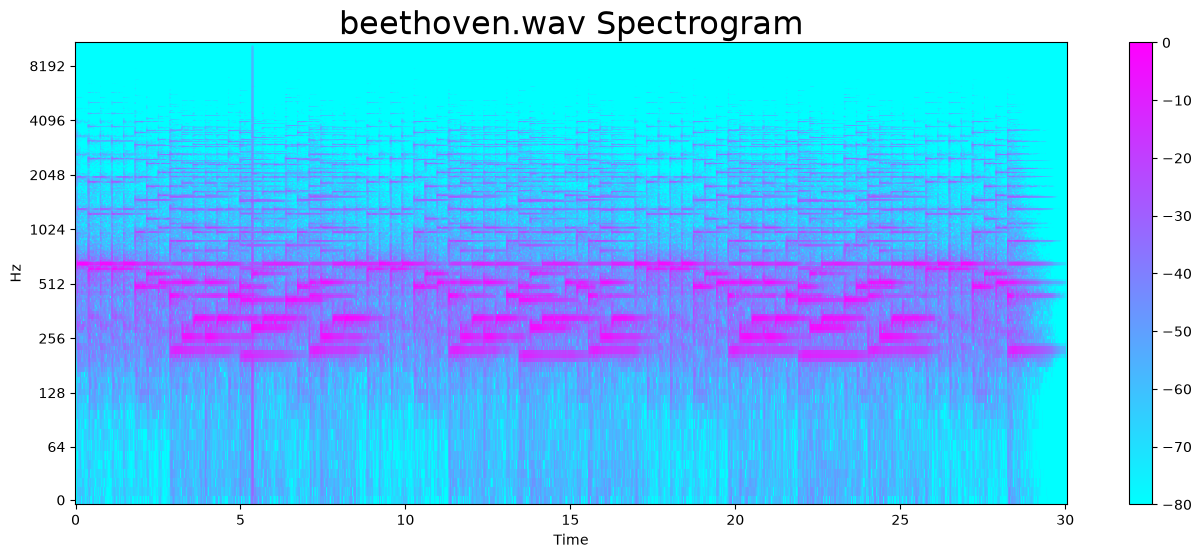

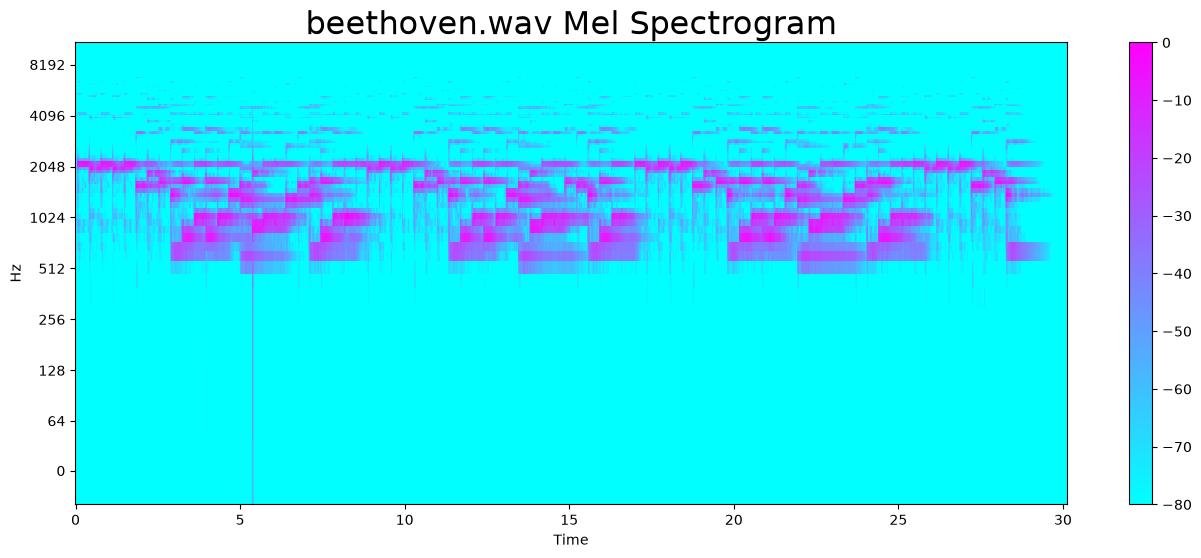

In [22]:
displaySpectogram('beethoven.wav')

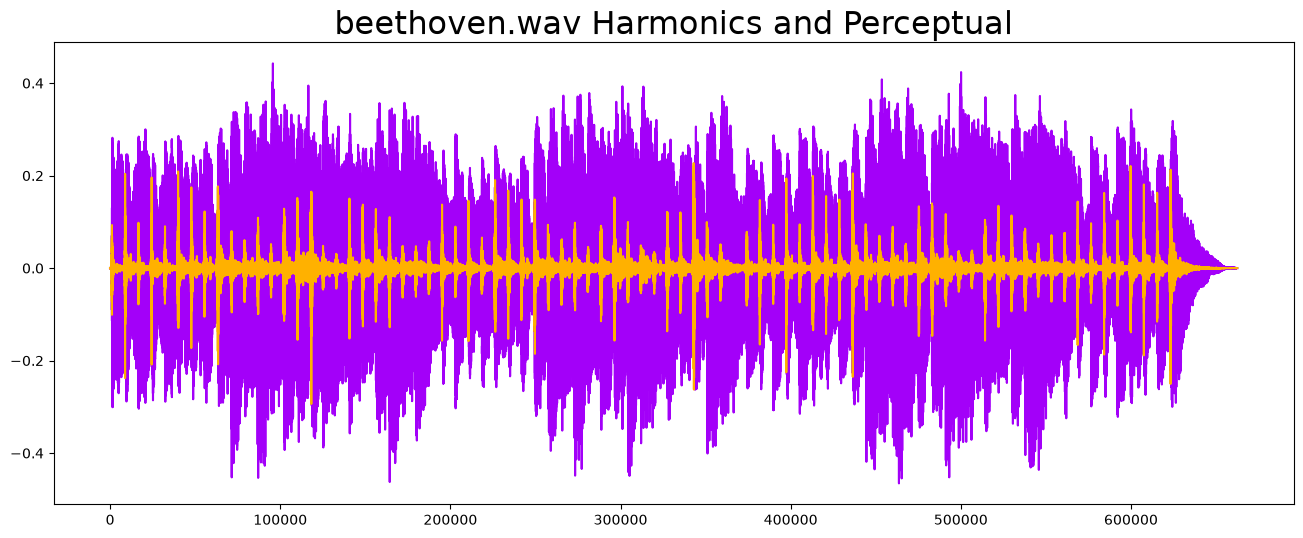

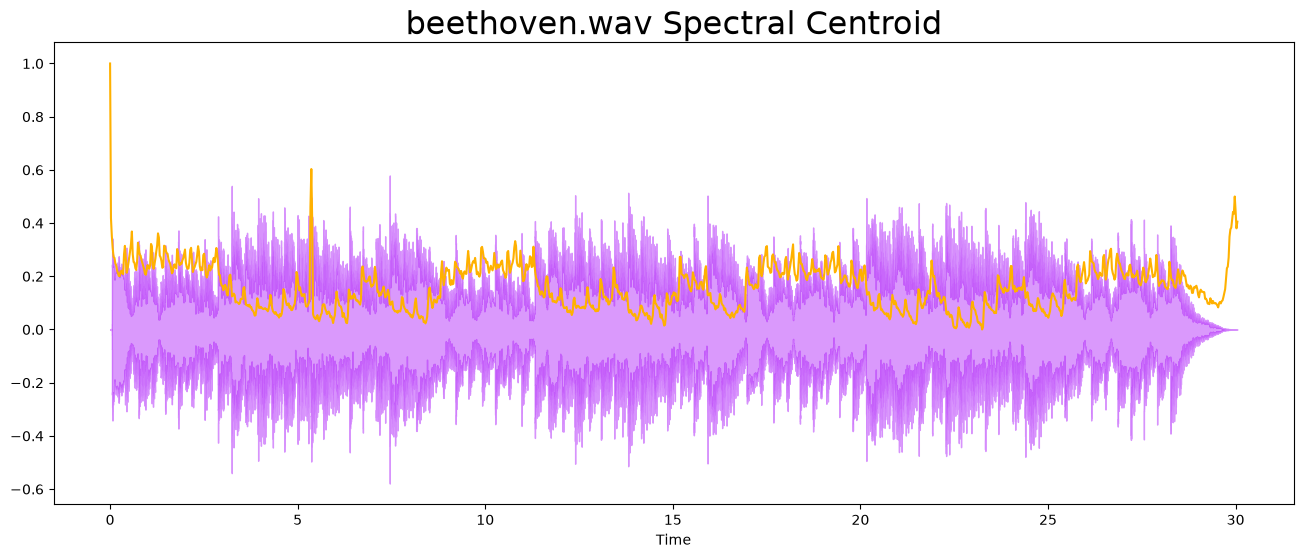

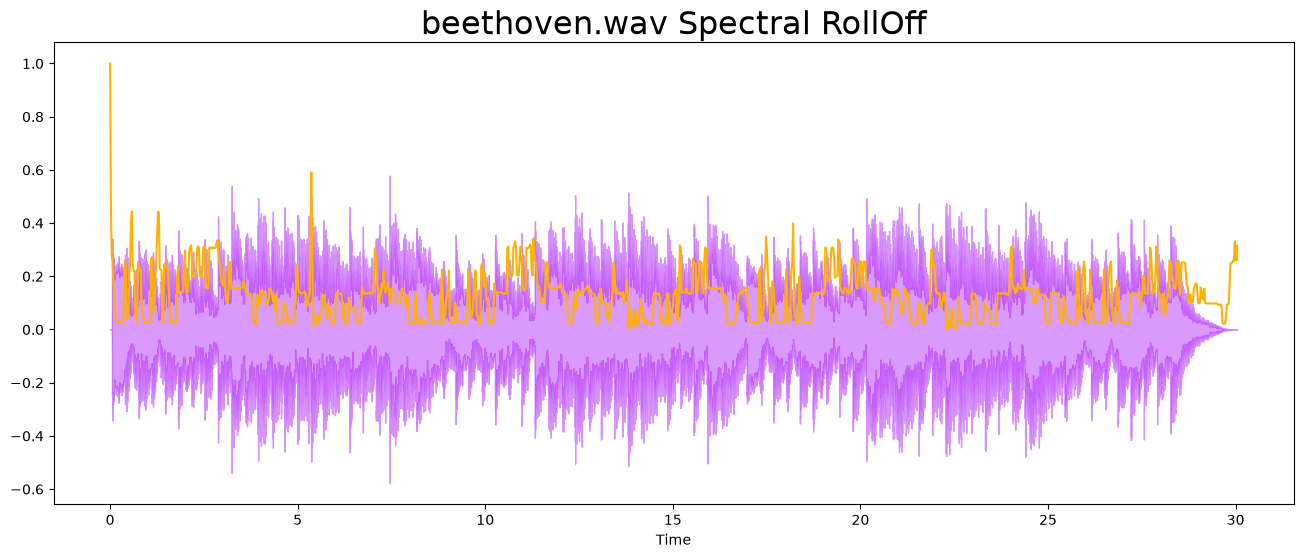

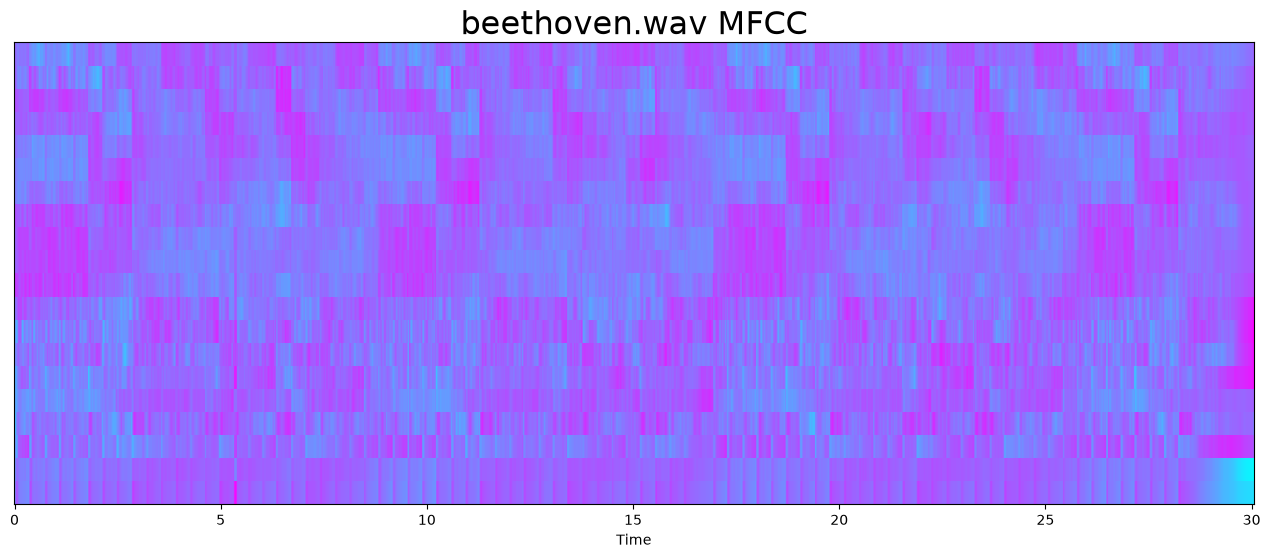

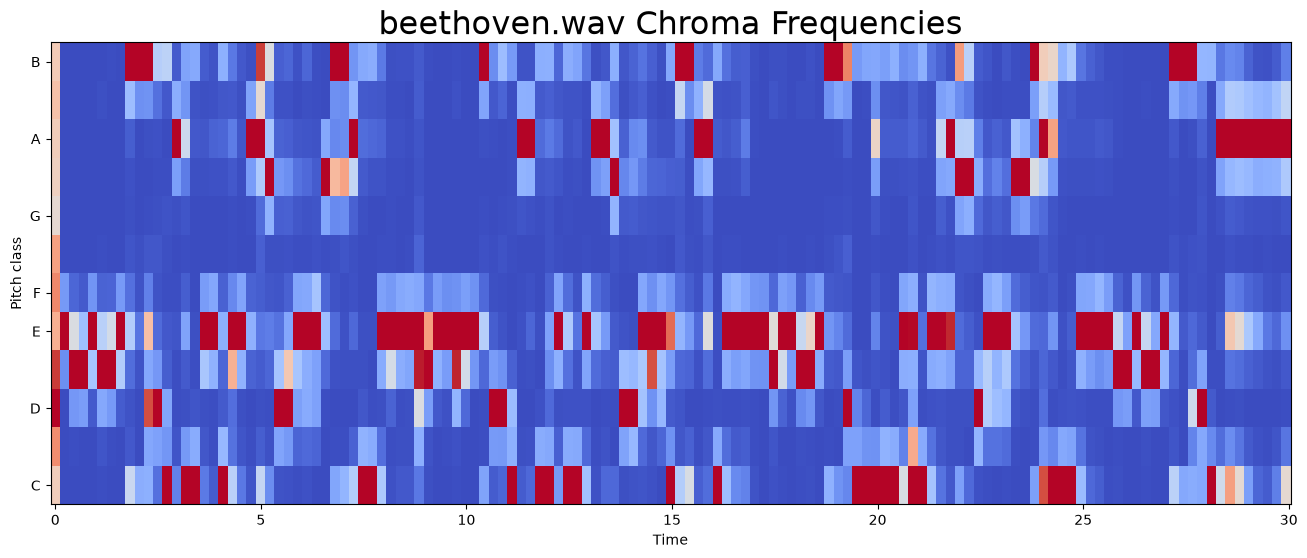

In [28]:
displayFeatures('beethoven.wav')